# Experiment2: Develop a LSTM-based model for time series data forecasting.

# multivariant

In [17]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tarit21/electricity-transformer-dataset-etdataset")

print("Path to dataset files:", path)

Path to dataset files: /home/rito/.cache/kagglehub/datasets/tarit21/electricity-transformer-dataset-etdataset/versions/1


In [18]:
seq_length = 48
batch_size = 5     
learning_rate = 0.0001
num_epochs = 100
dropout_num = 0.2

# Number of LSTM layers = number of past hours fed in, one per layer.
# 6 hours in (1 hour's 6 features per layer) -> predict the 7th hour's OT.
num_layers = 6


In [19]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

In [20]:
os.listdir(path + "/ETT-small")
path_data = path + "/ETT-small"

In [21]:
data = pd.read_csv(path_data + "/ETTh1.csv")

In [22]:
df = pd.DataFrame(data)

In [23]:
# Check dataset size
print("Total samples:", len(df))

# Chronological split
train_size = int(len(df) * 0.60)
val_size = int(len(df) * 0.20)

train = df.iloc[:train_size]
val = df.iloc[train_size:train_size + val_size]
test = df.iloc[train_size + val_size:]

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Total samples: 17420
Train: (10452, 8)
Validation: (3484, 8)
Test: (3484, 8)


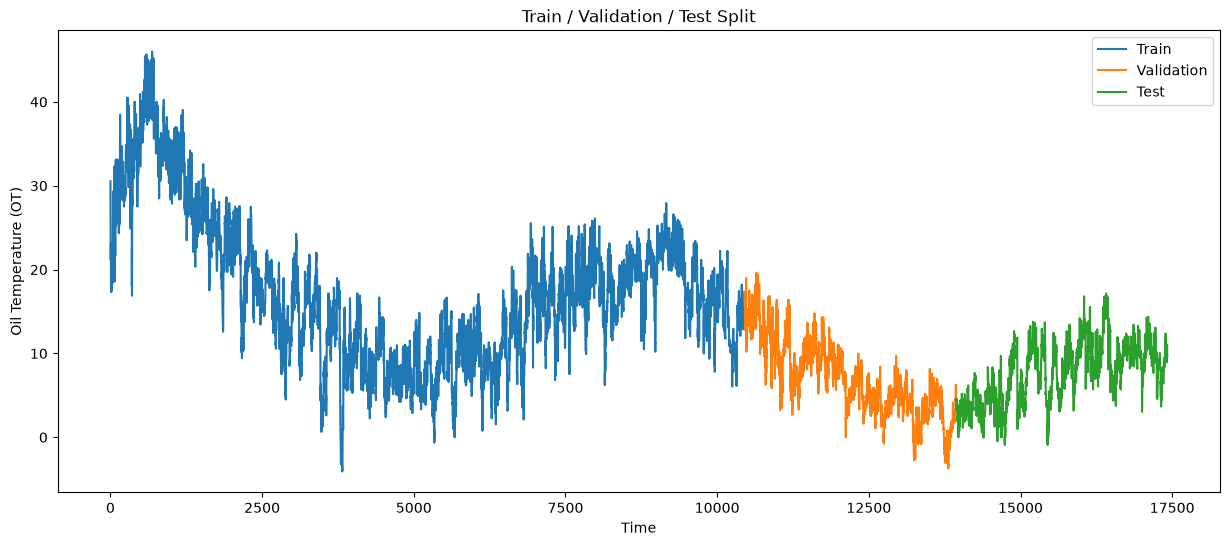

In [24]:
plt.figure(figsize=(15, 6))

plt.plot(train['OT'], label='Train')
plt.plot(val['OT'], label='Validation')
plt.plot(test['OT'], label='Test')

plt.xlabel('Time')
plt.ylabel('Oil Temperature (OT)')
plt.title('Train / Validation / Test Split')
plt.legend()
plt.show()

In [25]:
import torch.nn as nn

class LSTMModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        num_layers,
        output_size
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # Layer 0 only sees its own 6-dim data. Every later layer sees its
        # own 6-dim data concatenated with the previous layer's output, so
        # its input is bigger: input_size + hidden_size.
        self.lstm_cells = nn.ModuleList([
            nn.LSTMCell(
                input_size if i == 0 else input_size + hidden_size,
                hidden_size
            )
            for i in range(num_layers)
        ])

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        # x shape: (batch, num_layers, input_size) -> (batch, n, 6)
        batch_size = x.size(0)
        device = x.device

        prev_output = None

        for i, cell in enumerate(self.lstm_cells):

            x_i = x[:, i, :]

            # Feed the previous layer's output forward as part of this
            # layer's input (not as a carried-over hidden state).
            if prev_output is not None:
                x_i = torch.cat([x_i, prev_output], dim=1)

            # Each layer is its own single-step LSTM: fresh (h, c) start.
            h0 = torch.zeros(batch_size, self.hidden_size, device=device)
            c0 = torch.zeros(batch_size, self.hidden_size, device=device)

            h, c = cell(x_i, (h0, c0))

            prev_output = h

        # Last layer's output is used for the prediction
        out = self.fc(prev_output)

        return out


In [26]:
from sklearn.preprocessing import MinMaxScaler

features = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL']

target = 'OT'

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

# Training data: learn min/max AND scale
X_train = feature_scaler.fit_transform(train[features])
y_train = target_scaler.fit_transform(train[[target]])

# Validation/test: use the min/max learned from training
X_val = feature_scaler.transform(val[features])
y_val = target_scaler.transform(val[[target]])

X_test = feature_scaler.transform(test[features])
y_test = target_scaler.transform(test[[target]])


In [27]:
def create_sequences(X, y, seq_length):
    X_seq = []
    y_seq = []

    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i + seq_length])
        y_seq.append(y[i + seq_length])

    return np.array(X_seq), np.array(y_seq)

In [28]:
X_train_seq, y_train_seq = create_sequences(
    X_train, y_train, num_layers
)

X_val_seq, y_val_seq = create_sequences(
    X_val, y_val, num_layers
)

X_test_seq, y_test_seq = create_sequences(
    X_test, y_test, num_layers
)

print(X_train_seq.shape)
print(y_train_seq.shape)


(10446, 6, 6)
(10446, 1)


In [30]:
import torch

X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_seq, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_seq, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_seq, dtype=torch.float32)


In [32]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


In [33]:
model = LSTMModel(
    input_size=6,
    hidden_size=6,
    num_layers=num_layers,
    output_size=1
)

print(model)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)


LSTMModel(
  (lstm_cells): ModuleList(
    (0): LSTMCell(6, 6)
    (1-5): 5 x LSTMCell(12, 6)
  )
  (fc): Linear(in_features=6, out_features=1, bias=True)
)


In [34]:
# num_epochs = 40

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model.train()

    train_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)


    # --------------------
    # Validation
    # --------------------
    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )


Epoch [1/100] Train Loss: 0.119640 Val Loss: 0.048053
Epoch [2/100] Train Loss: 0.012268 Val Loss: 0.046681
Epoch [3/100] Train Loss: 0.011182 Val Loss: 0.044796
Epoch [4/100] Train Loss: 0.010727 Val Loss: 0.043734
Epoch [5/100] Train Loss: 0.010504 Val Loss: 0.042890
Epoch [6/100] Train Loss: 0.010330 Val Loss: 0.042072
Epoch [7/100] Train Loss: 0.010159 Val Loss: 0.041241
Epoch [8/100] Train Loss: 0.009983 Val Loss: 0.040382
Epoch [9/100] Train Loss: 0.009801 Val Loss: 0.039496
Epoch [10/100] Train Loss: 0.009614 Val Loss: 0.038594
Epoch [11/100] Train Loss: 0.009426 Val Loss: 0.037692
Epoch [12/100] Train Loss: 0.009240 Val Loss: 0.036809
Epoch [13/100] Train Loss: 0.009059 Val Loss: 0.035964
Epoch [14/100] Train Loss: 0.008889 Val Loss: 0.035178
Epoch [15/100] Train Loss: 0.008731 Val Loss: 0.034466
Epoch [16/100] Train Loss: 0.008588 Val Loss: 0.033837
Epoch [17/100] Train Loss: 0.008462 Val Loss: 0.033294
Epoch [18/100] Train Loss: 0.008352 Val Loss: 0.032834
Epoch [19/100] Trai

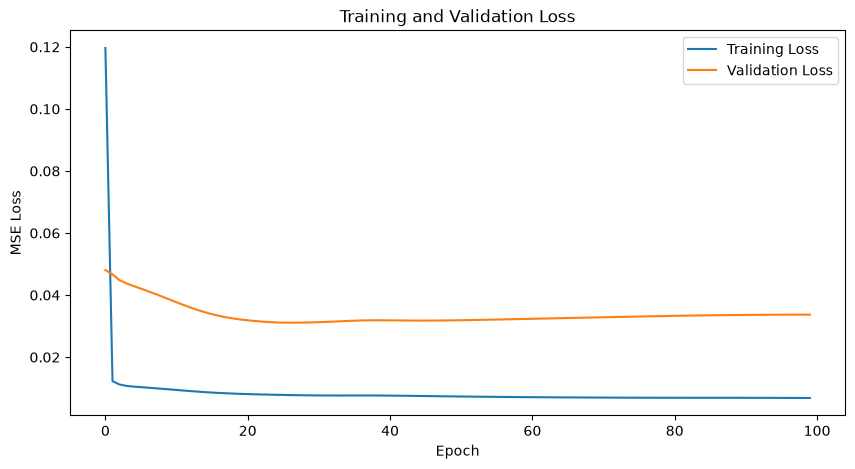

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training and Validation Loss')

plt.legend()
plt.show()


In [36]:
model.eval()

predictions = []
actuals = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        y_pred = model(X_batch)

        predictions.extend(y_pred.numpy())
        actuals.extend(y_batch.numpy())


predictions = np.array(predictions)
actuals = np.array(actuals)

print(predictions.shape)
print(actuals.shape)

predictions_original = target_scaler.inverse_transform(predictions)
actuals_original = target_scaler.inverse_transform(actuals)


(3478, 1)
(3478, 1)


In [37]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    actuals_original,
    predictions_original
)

print("MAE:", mae)


MAE: 7.889019966125488


In [38]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(
    mean_squared_error(
        actuals_original,
        predictions_original
    )
)

print("RMSE:", rmse)


RMSE: 8.409483560678636


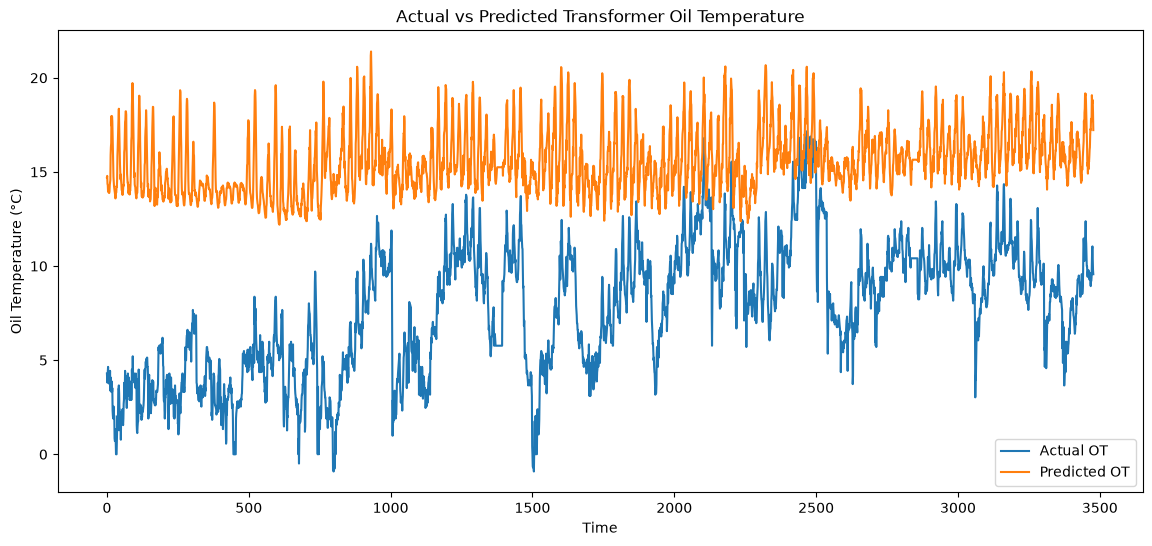

In [40]:
plt.figure(figsize=(14, 6))

plt.plot(
    actuals_original,
    label='Actual OT'
)

plt.plot(
    predictions_original,
    label='Predicted OT'
)

plt.xlabel('Time')
plt.ylabel('Oil Temperature (°C)')
plt.title('Actual vs Predicted Transformer Oil Temperature')

plt.legend()
plt.show()
